In [17]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("data")

image_paths = sorted(
    DATA_DIR.glob("s*/*.pgm"),
    key=lambda p: (
        int(p.parent.name[1:]),
        int(p.stem)
    )
)

images = []
labels = []

for path in image_paths:
    image = np.array(
        Image.open(path).convert("L"),
        dtype=np.uint8
    )

    images.append(image)
    labels.append(int(path.parent.name[1:]))

images = np.stack(images)
labels = np.array(labels)

print("Number of images:", len(images))
print("Image tensor shape:", images.shape)
print("Number of subjects:", len(np.unique(labels)))
print("Images per subject:", np.unique(labels, return_counts=True)[1])
print("Pixel intensity range:", images.min(), "to", images.max())
print("First image shape:", images[0].shape)
print("First image pixel values:\n", images[0][:5, :10])


Number of images: 400
Image tensor shape: (400, 112, 92)
Number of subjects: 40
Images per subject: [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]
Pixel intensity range: 0 to 251
First image shape: (112, 92)
First image pixel values:
 [[48 49 45 47 49 57 39 42 53 49]
 [45 52 39 46 56 45 39 47 48 40]
 [45 50 42 51 51 45 40 48 44 37]
 [49 46 47 47 50 47 42 45 40 44]
 [46 46 47 48 48 44 43 44 60 54]]


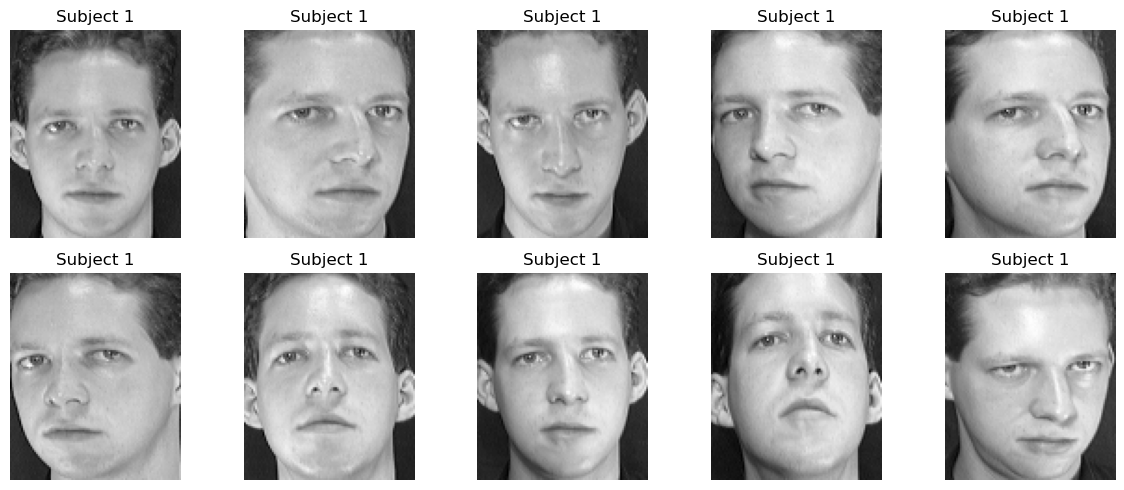

In [18]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {labels[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [19]:

X = images.reshape(images.shape[0], -1)

y = labels.copy()

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Features per image:", X.shape[1])
print("First 10 features:", X[0, :10])


Feature matrix shape: (400, 10304)
Label vector shape: (400,)
Features per image: 10304
First 10 features: [48 49 45 47 49 57 39 42 53 49]


In [20]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training subjects:", len(np.unique(y_train)))
print("Testing subjects:", len(np.unique(y_test)))

print("Training images per subject:",
      np.unique(y_train, return_counts=True)[1][:5])

print("Testing images per subject:",
      np.unique(y_test, return_counts=True)[1][:5])


Training samples: 320
Testing samples: 80
Training subjects: 40
Testing subjects: 40
Training images per subject: [8 8 8 8 8]
Testing images per subject: [2 2 2 2 2]


Mean face shape: (10304,)
Centered training shape: (320, 10304)
Centered test shape: (80, 10304)


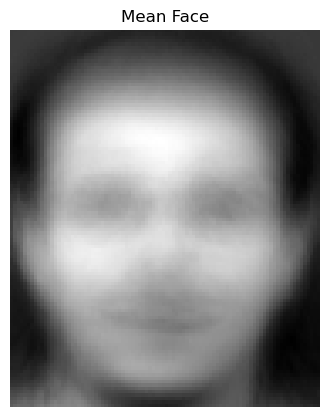

Mean of centered training features: 6.228282210195288e-16


In [21]:

X_train_float = X_train.astype(np.float64)
X_test_float = X_test.astype(np.float64)

mean_face = np.mean(X_train_float, axis=0)

X_train_centered = X_train_float - mean_face
X_test_centered = X_test_float - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training shape:", X_train_centered.shape)
print("Centered test shape:", X_test_centered.shape)

plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(112, 92), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

print("Mean of centered training features:",
      X_train_centered.mean())


In [22]:

n_samples = X_train_centered.shape[0]

C_dual = (
    X_train_centered @ X_train_centered.T
) / (n_samples - 1)

eigenvalues_dual, eigenvectors_dual = np.linalg.eigh(C_dual)

order = np.argsort(eigenvalues_dual)[::-1]
eigenvalues_dual = eigenvalues_dual[order]
eigenvectors_dual = eigenvectors_dual[:, order]

positive = eigenvalues_dual > 1e-10
eigenvalues_dual = eigenvalues_dual[positive]
eigenvectors_dual = eigenvectors_dual[:, positive]

components_dual = (
    X_train_centered.T @ eigenvectors_dual
) / np.sqrt(
    (n_samples - 1) * eigenvalues_dual
)

U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

eigenvalues_svd = singular_values**2 / (n_samples - 1)
components_svd = Vt.T

print("Dual covariance components:", components_dual.shape)
print("SVD components:", components_svd.shape)

variance_dual = eigenvalues_dual / eigenvalues_dual.sum()
variance_svd = eigenvalues_svd / eigenvalues_svd.sum()

print(
    "Top 5 dual covariance eigenvalues:",
    eigenvalues_dual[:5]
)
print(
    "Top 5 SVD eigenvalues:",
    eigenvalues_svd[:5]
)
print(
    "Top 5 SVD explained variance ratios:",
    variance_svd[:5]
)


Dual covariance components: (10304, 319)
SVD components: (10304, 320)
Top 5 dual covariance eigenvalues: [2881154.3084197  2069914.34945378 1093804.25057136  871380.92597549
  809594.92895779]
Top 5 SVD eigenvalues: [2881154.3084197  2069914.34945377 1093804.25057136  871380.92597549
  809594.92895779]
Top 5 SVD explained variance ratios: [0.17940463 0.12889009 0.06810935 0.05425943 0.05041211]


Components needed for 90% variance: 98
Variance preserved: 90.06%


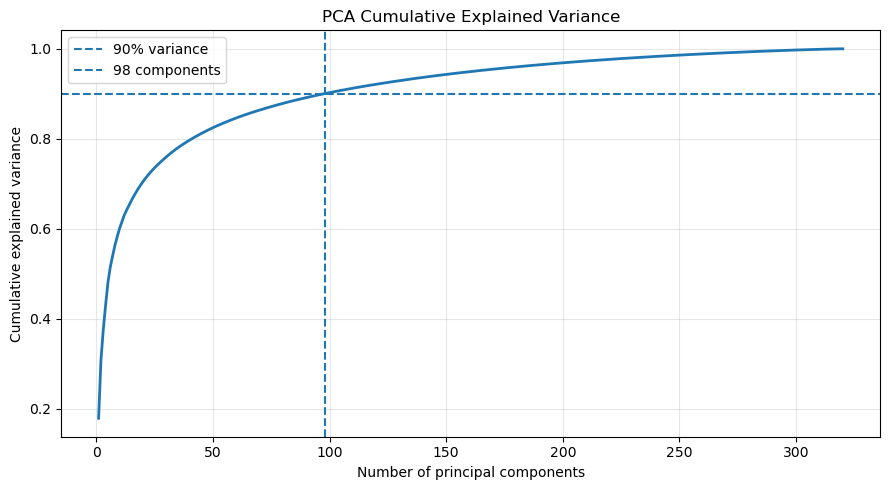

In [23]:

cumulative_variance = np.cumsum(variance_svd)

n_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print("Components needed for 90% variance:", n_90)
print(
    "Variance preserved:",
    f"{cumulative_variance[n_90 - 1] * 100:.2f}%"
)

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axvline(
    n_90,
    linestyle="--",
    label=f"{n_90} components"
)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


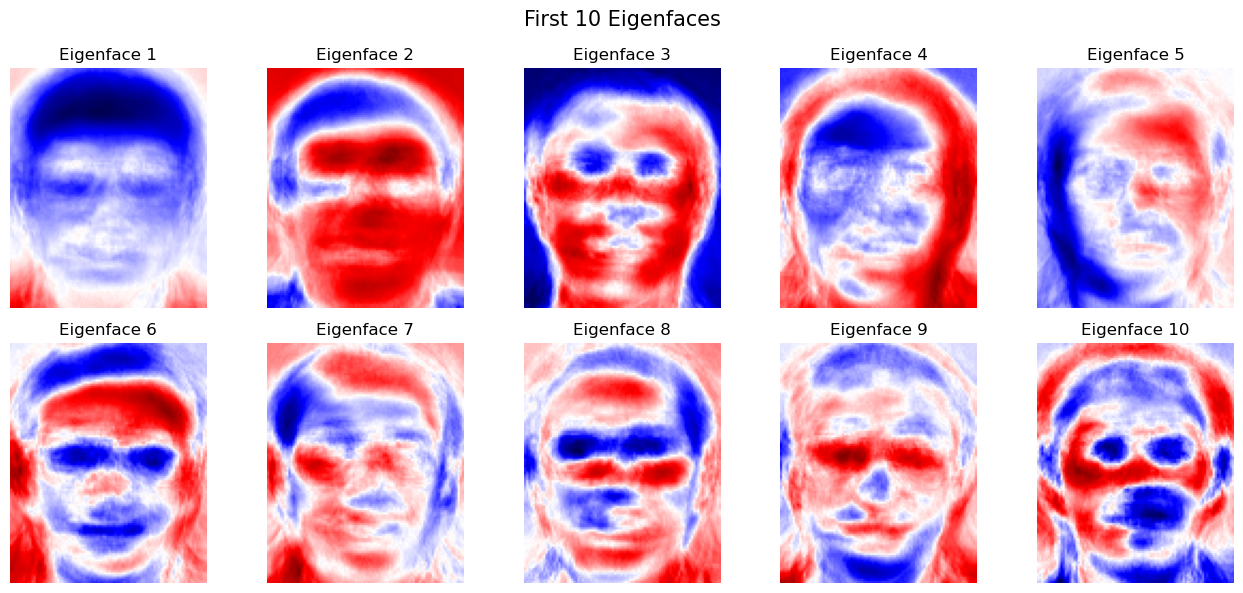

In [24]:

n_components = n_90
components = components_svd[:, :n_components]

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    eigenface = components[:, i].reshape(112, 92)

    limit = np.max(np.abs(eigenface))
    ax.imshow(
        eigenface,
        cmap="seismic",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("First 10 Eigenfaces", fontsize=15)
plt.tight_layout()
plt.show()


In [25]:

Z_train = X_train_centered @ components
Z_test = X_test_centered @ components

print("Training PCA representation:", Z_train.shape)
print("Test PCA representation:", Z_test.shape)

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

np.save(results_dir / "Z_train.npy", Z_train)
np.save(results_dir / "Z_test.npy", Z_test)
np.save(results_dir / "y_train.npy", y_train)
np.save(results_dir / "y_test.npy", y_test)

print("Reduced representations saved.")


Training PCA representation: (320, 98)
Test PCA representation: (80, 98)
Reduced representations saved.


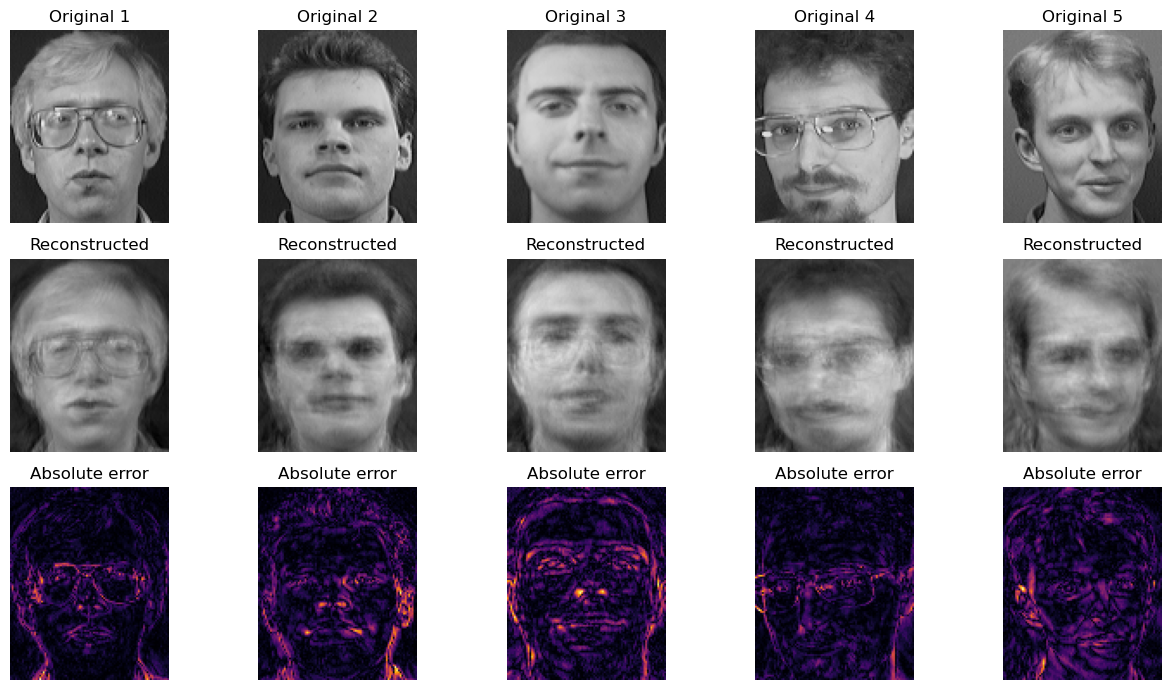

Reconstruction MSE: 329.9830
Reconstruction RMSE: 18.1654


In [26]:

X_test_reconstructed = Z_test @ components.T + mean_face

n_show = 5

fig, axes = plt.subplots(3, n_show, figsize=(13, 7))

for i in range(n_show):
    original = X_test_float[i].reshape(112, 92)
    reconstructed = X_test_reconstructed[i].reshape(112, 92)

    axes[0, i].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(f"Original {i + 1}")

    axes[1, i].imshow(
        reconstructed, cmap="gray", vmin=0, vmax=255
    )
    axes[1, i].set_title("Reconstructed")

    axes[2, i].imshow(
        np.abs(original - reconstructed), cmap="inferno"
    )
    axes[2, i].set_title("Absolute error")

    for ax in axes[:, i]:
        ax.axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
axes[2, 0].set_ylabel("Error")

plt.tight_layout()
plt.show()

mse = np.mean((X_test_float - X_test_reconstructed) ** 2)
rmse = np.sqrt(mse)

print(f"Reconstruction MSE: {mse:.4f}")
print(f"Reconstruction RMSE: {rmse:.4f}")


In [27]:

original_features = X.shape[1]
reduced_features = n_components

print("Original features per image:", original_features)
print("PCA features per image:", reduced_features)

print(
    f"Feature reduction: "
    f"{(1 - reduced_features / original_features) * 100:.2f}%"
)

original_bytes = original_features * np.dtype(np.float64).itemsize
reduced_bytes = reduced_features * np.dtype(np.float64).itemsize

print(f"Original float64 storage: {original_bytes:,} bytes")
print(f"Reduced float64 storage: {reduced_bytes:,} bytes")
print(f"Score storage ratio: {original_bytes / reduced_bytes:.2f}x")


Original features per image: 10304
PCA features per image: 98
Feature reduction: 99.05%
Original float64 storage: 82,432 bytes
Reduced float64 storage: 784 bytes
Score storage ratio: 105.14x


In [28]:

def nearest_neighbor_predict(X_reference, y_reference, X_query):
    """Predict labels using the nearest reference vector."""
    # Squared Euclidean distances; shape = (queries, references)
    query_norms = np.sum(X_query**2, axis=1, keepdims=True)
    reference_norms = np.sum(
        X_reference**2, axis=1
    )[None, :]

    distances_squared = (
        query_norms
        + reference_norms
        - 2 * X_query @ X_reference.T
    )

    # Protect against tiny negative values from floating-point error
    np.maximum(distances_squared, 0, out=distances_squared)

    nearest_indices = np.argmin(distances_squared, axis=1)
    predictions = y_reference[nearest_indices]

    return predictions, nearest_indices


raw_predictions, raw_match_indices = nearest_neighbor_predict(
    X_train_float,
    y_train,
    X_test_float
)

pca_predictions, pca_match_indices = nearest_neighbor_predict(
    Z_train,
    y_train,
    Z_test
)

raw_accuracy = np.mean(raw_predictions == y_test)
pca_accuracy = np.mean(pca_predictions == y_test)

print(f"Raw-pixel 1-NN accuracy: {raw_accuracy:.4f} "
      f"({np.sum(raw_predictions == y_test)}/{len(y_test)})")

print(f"PCA-space 1-NN accuracy: {pca_accuracy:.4f} "
      f"({np.sum(pca_predictions == y_test)}/{len(y_test)})")


Raw-pixel 1-NN accuracy: 0.9500 (76/80)
PCA-space 1-NN accuracy: 0.9500 (76/80)


In [29]:

import pandas as pd

baseline_results = pd.DataFrame({
    "Method": ["Raw pixels + 1-NN", f"PCA ({n_components} components) + 1-NN"],
    "Features per image": [X_train_float.shape[1], Z_train.shape[1]],
    "Correct predictions": [
        int(np.sum(raw_predictions == y_test)),
        int(np.sum(pca_predictions == y_test))
    ],
    "Accuracy (%)": [
        raw_accuracy * 100,
        pca_accuracy * 100
    ]
})

display(baseline_results)


,Method,Features per image,Correct predictions,Accuracy (%)
0,Raw pixels + 1-NN,10304,76,95.0
1,PCA (98 components) + 1-NN,98,76,95.0


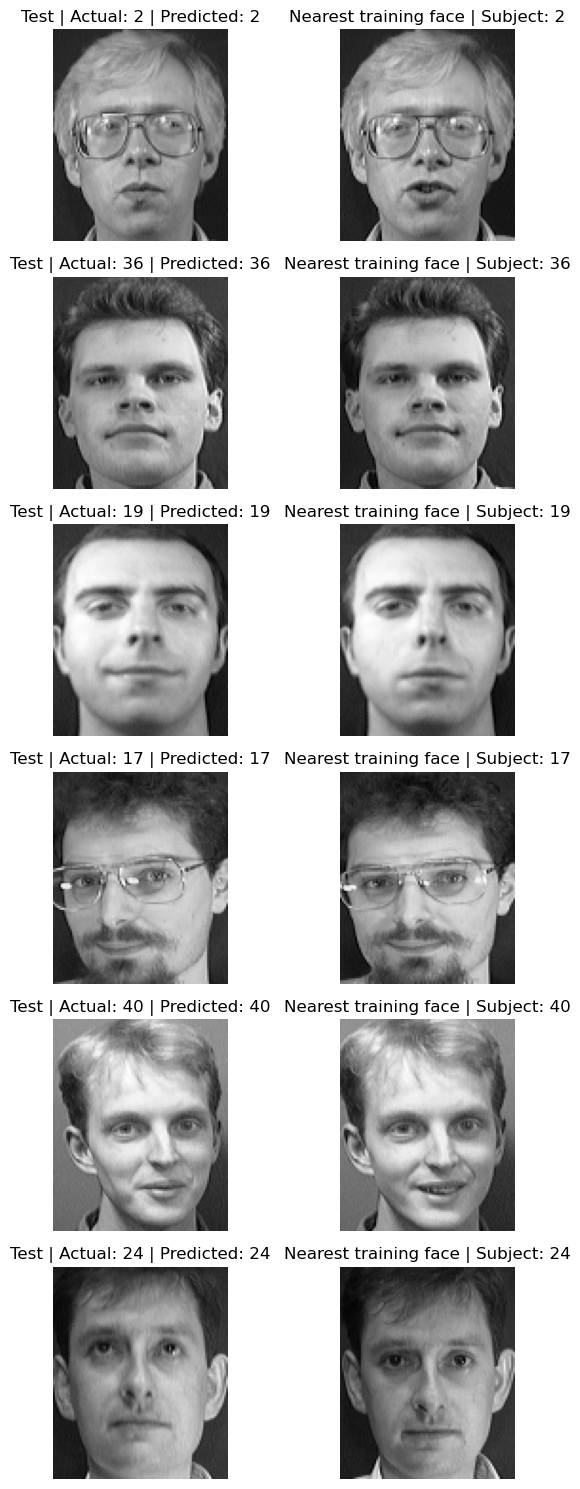

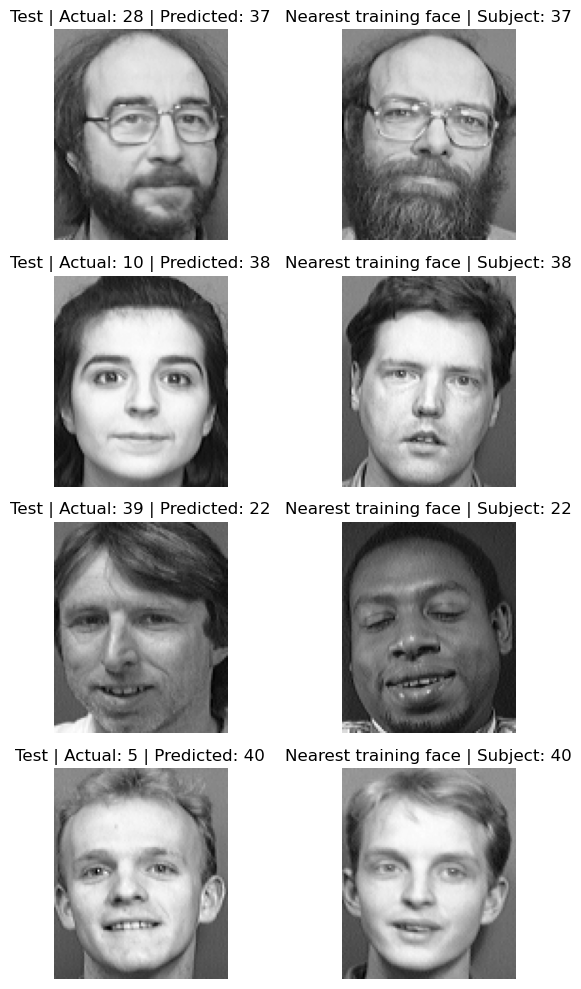

In [30]:

def show_matches(
    query_images, reference_images, y_true,
    y_pred, match_indices, max_examples=8,
    only_errors=False
):
    if only_errors:
        selected = np.flatnonzero(y_true != y_pred)
    else:
        selected = np.arange(len(y_true))

    selected = selected[:max_examples]

    if len(selected) == 0:
        print("No examples to display.")
        return

    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(7, 2.5 * len(selected)),
        squeeze=False
    )

    for row, idx in enumerate(selected):
        match_idx = match_indices[idx]

        axes[row, 0].imshow(
            query_images[idx], cmap="gray"
        )
        axes[row, 0].set_title(
            f"Test | Actual: {y_true[idx]} | Predicted: {y_pred[idx]}"
        )

        axes[row, 1].imshow(
            reference_images[match_idx], cmap="gray"
        )
        axes[row, 1].set_title(
            f"Nearest training face | Subject: {y_train[match_idx]}"
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()


show_matches(
    X_test_float.reshape(-1, 112, 92),
    X_train_float.reshape(-1, 112, 92),
    y_test,
    pca_predictions,
    pca_match_indices,
    max_examples=6
)

show_matches(
    X_test_float.reshape(-1, 112, 92),
    X_train_float.reshape(-1, 112, 92),
    y_test,
    pca_predictions,
    pca_match_indices,
    max_examples=6,
    only_errors=True
)


In [31]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

component_counts = [20, 50, 98, 150, 200]
ml_results = []

for k in component_counts:
    # Use the first k NumPy-computed principal components
    Ztr = X_train_centered @ components_svd[:, :k]
    Zte = X_test_centered @ components_svd[:, :k]

    models = {
        "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
        "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
        "SVM (RBF)": SVC(C=10, kernel="rbf"),
        "Logistic Regression": LogisticRegression(
            max_iter=3000
        )
    }

    for name, model in models.items():
        # Scaling is fitted only on training features
        classifier = make_pipeline(
            StandardScaler(),
            model
        )

        classifier.fit(Ztr, y_train)
        predictions = classifier.predict(Zte)
        accuracy = accuracy_score(y_test, predictions)

        ml_results.append({
            "Components": k,
            "Features": k,
            "Classifier": name,
            "Accuracy (%)": round(accuracy * 100, 2)
        })

ml_results_df = pd.DataFrame(ml_results)

display(
    ml_results_df.sort_values(
        "Accuracy (%)", ascending=False
    ).reset_index(drop=True)
)

results_dir.mkdir(exist_ok=True)
ml_results_df.to_csv(
    results_dir / "ml_comparison.csv",
    index=False
)


,Components,Features,Classifier,Accuracy (%)
0,50,50,Logistic Regression,98.75
1,50,50,SVM (RBF),97.50
2,20,20,SVM (RBF),96.25
3,98,98,SVM (RBF),95.00
4,98,98,Logistic Regression,95.00
5,50,50,KNN (k=1),93.75
6,200,200,Logistic Regression,93.75
7,150,150,Logistic Regression,93.75
8,20,20,KNN (k=1),92.50
9,20,20,Logistic Regression,92.50


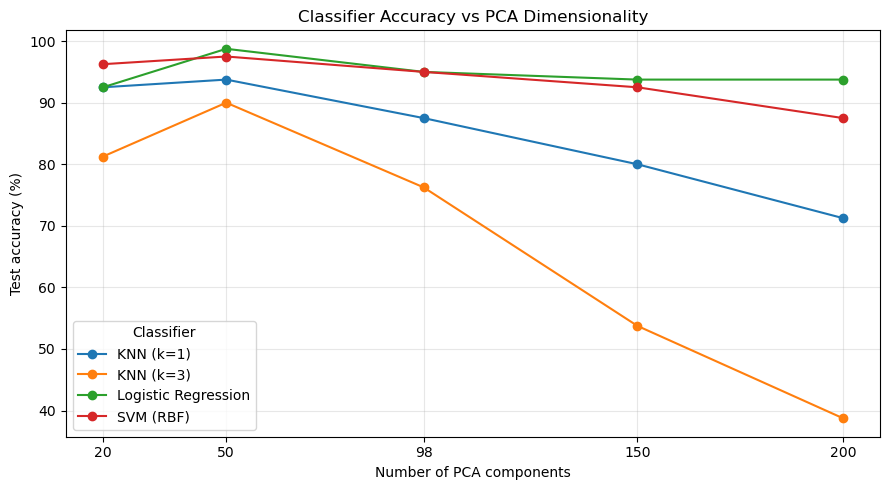

In [32]:

pivot = ml_results_df.pivot(
    index="Components",
    columns="Classifier",
    values="Accuracy (%)"
)

ax = pivot.plot(
    marker="o",
    figsize=(9, 5)
)

ax.set_xlabel("Number of PCA components")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Classifier Accuracy vs PCA Dimensionality")
ax.set_xticks(component_counts)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
